# Colab G4：IPPO + Muon 训练参数与实测结果

**推荐默认值：rollout 1024 / collect 2048 / mini_batches 16 / OMP threads 6。**

2026-10-10 实测：双种子合并 **271.92 局/秒**（约 15753 游戏动作/秒），比原 G4 参数的 221.25 局/秒提高 **22.9%**。45 次测试中 38 次完成、7 次失败；所有参数、568 轮的 23 项原始训练字段、8742 条 GPU 采样、失败日志和 2 个 checkpoint 已保存。最优 checkpoint 已通过模型与优化器恢复验证。

| 配置 | 复测吞吐（局/秒） | 游戏动作/秒 | 显存峰值（GiB） | 测试 |
|---|---:|---:|---:|---|
| 原 G4：R256 C224 M3 T6 | 221.25 | 13666 | 12.49 | 历史 seed 0，40 轮 |
| R1024 C2048 M16 T6 | 271.92 | 15753 | 94.87 | seed 0 / 1，各 40 轮 |
| R1536 C2048 M16 T6 | 270.89 | 15823 | 94.71 | seed 0 / 1，各 40 轮 |

R 是并行环境数，C 是每轮采样对局数，M 是 mini-batch 数，T 是 CPU 线程数。合并吞吐按两次测量的总对局数 / 总耗时计算。

**显存余量很小：最优配置采样峰值 94.87 GiB。** 两个种子通过不能保证长期训练永不 OOM。较低显存的短测候选为 R1024 C1024 M2 T6：255.45 局/秒、峰值 52.17 GiB；该候选仅完成 12 轮筛选，尚未做双种子 40 轮复测。

硬件为 NVIDIA RTX PRO 6000 Blackwell Server Edition（CUDA 可见 94.97 GiB）、AMD EPYC 9B45、48 CPU 线程。软件为 Python 3.13.15、PyTorch 2.11.0+cu130、CUDA 13.0。固定完整斗地主、v1.3 模型、每轮 4 个 PPO epoch 及其余原训练超参数；仓库提交 `acdcf199cf422e2b683cb22142b8e7cb33b14460`。

默认模式仅复测推荐参数；设置环境变量 `G4_TUNE=1` 可重跑完整调优。先验证 [私有 Drive doudizhu 目录](https://drive.google.com/drive/folders/14wacgMnsJwnldEKydfQ5TFCUb5EOGTEO) 可读写，再申请 G4。本次已在申请前完成 notebook、多个候选及 Drive 写入读回检查。最大配置 R4096 C4096 M4 T6 首先测试并 OOM，随后缩小；所有实验连续使用同一 runtime。

筛选：12 轮、预热 3 轮、8 个完整计时间隔。复测：40 轮、预热 8 轮、31 个间隔；排除安装、首次初始化和预热，计入采样、前向、反向和优化器。GPU 每 500 ms 采样，可能漏掉瞬时峰值。seed 0 保存第 40 轮 checkpoint，seed 1 仅记录完整数值与日志。

完整结果：[参数、全部原始指标和日志、checkpoint 与 SHA256 清单](https://drive.google.com/file/d/1065jPNueS_PyELbVP8VO6cf9rEoVyGwO/view)。浏览器运行将结果写入 `/content/drive/MyDrive/doudizhu/<run_id>`；CLI 模式先通过 Drive connector 验证目录，再下载并上传。自动化操作方必须在结束后 `colab stop` 并核实活动资源为 0。

本次 G4 runtime 已删除，服务器活动会话为 0、消耗速率为 0.00 单位/小时。账户前后余额差 10.48 单位；该差值可能受结算延迟或其他账户活动影响。

本文件合并同一个 G4 kernel 中实际运行的主测试、追加组合测试和 checkpoint 检查输出；默认推荐值已更新并通过参数自检。吞吐优化会改变更新频率及学习行为，未验证棋力、长期收敛或所有参数空间的全局最优。


### 1. G4 专用参数与预先准备的测试计划

In [ ]:
# @title 1. G4 专用参数与预先准备的测试计划
import csv
from dataclasses import asdict
from datetime import datetime, timezone
import hashlib
import json
import math
import os
from pathlib import Path
import signal
import statistics
import subprocess
import sys
import time
import shutil

REPO_URL = "https://github.com/GentleKingson/doudizhu.git"
COMMIT = "acdcf199cf422e2b683cb22142b8e7cb33b14460"
RUN_TUNING = os.environ.get("G4_TUNE", "0") == "1"
BASELINE = dict(rollout=256, collect=224, mini_batches=3, threads=6)
RECOMMENDED = {'rollout': 1024, 'collect': 2048, 'mini_batches': 16, 'threads': 6}
SCREEN_ITERATIONS, SCREEN_WARMUP = 12, 3
VERIFY_ITERATIONS, VERIFY_WARMUP = 40, 8
TRIAL_TIMEOUT = 900
RUN_ID = os.environ.get("G4_RUN_ID", "g4-ippo-muon-" + datetime.now(timezone.utc).strftime("%Y%m%d-%H%M%S"))
CAPACITY_LADDER = [dict(rollout=n, collect=n, mini_batches=4, threads=6)
                   for n in (4096, 2048, 1024, 512, 256)]
MINI_BATCH_CHOICES = (1, 2, 4, 8, 16)
THREAD_CHOICES = (1, 6, 12, 24)
SCALE_CHOICES = (0.5, 0.75, 1.25, 2.0)
os.environ.update(OMP_NUM_THREADS="6", WANDB_DISABLED="true",
                  PYTORCH_ALLOC_CONF="expandable_segments:True")

def validate_config(config):
    assert set(config) == {"rollout", "collect", "mini_batches", "threads"}
    assert all(isinstance(v, int) and v > 0 for v in config.values())
    assert 64 <= config["rollout"] <= 4096 and 64 <= config["collect"] <= 4096
    assert config["mini_batches"] <= config["collect"] and config["threads"] <= 48
    return config

def summarize(events, collect, warmup):
    measured = events[warmup:]
    elapsed = measured[-1]["seconds"] - measured[0]["seconds"]
    intervals = len(measured) - 1
    assert intervals > 0 and elapsed > 0
    steps = measured[-1]["statistics/game_steps_total"] - measured[0]["statistics/game_steps_total"]
    return dict(steady_seconds=elapsed, measured_iterations=intervals,
                measured_games=collect * intervals, games_per_second=collect * intervals / elapsed,
                game_steps_per_second=steps / elapsed, seconds_per_iteration=elapsed / intervals,
                first_iteration_seconds=events[0]["seconds"])

example = [dict(seconds=t, **{"statistics/game_steps_total": t * 10}) for t in (10, 12, 14, 16)]
assert summarize(example, 32, 1)["games_per_second"] == 16
assert summarize(example, 32, 1)["game_steps_per_second"] == 10
assert SCREEN_ITERATIONS > SCREEN_WARMUP + 2 and VERIFY_ITERATIONS > VERIFY_WARMUP + 2
assert CAPACITY_LADDER[0]["rollout"] == max(c["rollout"] for c in CAPACITY_LADDER)
for config in [RECOMMENDED, *CAPACITY_LADDER]:
    validate_config(config)
assert Path(RUN_ID).name == RUN_ID and RUN_ID not in (".", "..")
print("PASS: 参数边界、最大配置优先及测速公式自检")

PASS: 参数边界、最大配置优先及测速公式自检


### 2. 先验证结果目录，再安装训练环境

In [ ]:
# @title 2. 先验证结果目录，再安装训练环境
if os.environ.get("G4_RESULT_ROOT"):
    assert os.environ.get("G4_DRIVE_VERIFIED") == "1", "CLI 模式必须先通过 Drive 写入和读回检查"
    result_root = Path(os.environ["G4_RESULT_ROOT"])
    persistence_mode = "CLI 下载后通过已验证的 Google Drive connector 上传"
else:
    from google.colab import drive
    drive.mount("/content/drive")
    result_root = Path("/content/drive/MyDrive/doudizhu")
    assert result_root.is_dir(), "请先在 Google Drive 建立 doudizhu 目录"
    persistence_mode = "Google Drive mount"
result_root.mkdir(parents=True, exist_ok=True)
OUTPUT = result_root / RUN_ID
OUTPUT.mkdir(exist_ok=False)
probe = OUTPUT / "write-check.txt"
probe.write_text("doudizhu G4 write/read check", encoding="utf-8")
assert probe.read_text(encoding="utf-8") == "doudizhu G4 write/read check"
probe.unlink()
WORK = Path("/content") / (RUN_ID + "-environment")
WORK.mkdir(exist_ok=False)
repo, python = WORK / "repo", WORK / "venv/bin/python"
results, screen_results = [], []
(OUTPUT / "prepared-plan.json").write_text(json.dumps(dict(
    repository=REPO_URL, commit=COMMIT, capacity_ladder=CAPACITY_LADDER,
    mini_batch_choices=MINI_BATCH_CHOICES, thread_choices=THREAD_CHOICES,
    scale_choices=SCALE_CHOICES, screen_iterations=SCREEN_ITERATIONS,
    screen_warmup=SCREEN_WARMUP, verify_iterations=VERIFY_ITERATIONS,
    verify_warmup=VERIFY_WARMUP, seeds=[0, 1], persistence_mode=persistence_mode), indent=2))
setup_started = time.monotonic()
with (OUTPUT / "setup.log").open("w") as setup_log:
    def setup_command(command, **kwargs):
        subprocess.run(command, check=True, stdout=setup_log,
                       stderr=subprocess.STDOUT, timeout=600, **kwargs)
    setup_command(["git", "clone", "--quiet", "--no-checkout", REPO_URL, str(repo)])
    setup_command(["git", "checkout", "--quiet", COMMIT], cwd=repo)
    assert subprocess.check_output(["git", "rev-parse", "HEAD"], cwd=repo, text=True).strip() == COMMIT
    setup_command([sys.executable, "-m", "venv", "--without-pip", "--system-site-packages", str(WORK / "venv")])
    setup_command([str(python), "-m", "pip", "install", "--disable-pip-version-check",
                   "setuptools>=64", "wheel", "cmake==3.31.10", "ninja", "numpy==2.5.3", "tyro==1.0.16", "tqdm"])
    setup_command([str(python), "-m", "pip", "install", "--no-deps", "-e", str(repo)])
    setup_command([str(python), "-m", "pip", "install", "--no-deps", "--no-build-isolation", "-e", str(repo / "nanopokerlib")],
                  env=dict(os.environ, NANOPOKERLIB_BUILD_JOBS="8"))
setup_seconds = time.monotonic() - setup_started
print(f"目录读写通过；安装完成 {setup_seconds:.1f} 秒", flush=True)

目录读写通过；安装完成 80.0 秒


### 3. 核实 G4 硬件与完整训练默认值

In [ ]:
# @title 3. 核实 G4 硬件与完整训练默认值
hardware_code = """
from dataclasses import asdict
import json, os, platform, subprocess, torch
from marvel.config import TrainConfig
assert torch.cuda.is_available() and torch.cuda.device_count() == 1
p = torch.cuda.get_device_properties(0)
cpu = next(line.split(':',1)[1].strip() for line in open('/proc/cpuinfo') if line.startswith('model name'))
ram = int(next(line.split()[1] for line in open('/proc/meminfo') if line.startswith('MemTotal:')))
print(json.dumps(dict(hardware=dict(gpu=p.name, gpu_total_mib=p.total_memory/1024**2,
    cpu=cpu, cpu_count=os.cpu_count(), cpu_affinity_count=len(os.sched_getaffinity(0)),
    ram_gib=ram/1024**2, python=platform.python_version(), torch=torch.__version__, cuda=torch.version.cuda,
    driver=subprocess.check_output(['nvidia-smi','--query-gpu=driver_version','--format=csv,noheader'],text=True).strip()),
    config=asdict(TrainConfig(algo_name='ippo', game_name='doudizhu', device='cuda')))))
"""
environment = json.loads(subprocess.check_output([str(python), "-c", hardware_code], cwd=repo, text=True))
hardware, base_config = environment["hardware"], environment["config"]
assert "RTX PRO 6000" in hardware["gpu"] and "Blackwell" in hardware["gpu"], hardware
assert base_config["optimizer"]["use_muon"] and base_config["ppo"]["agent_epoch"] == 4
assert base_config["model"]["architecture"] == "v1.3"
environment.update(commit=COMMIT, setup_seconds=setup_seconds, run_id=RUN_ID)
(OUTPUT / "environment.json").write_text(json.dumps(environment, indent=2))
print(json.dumps(hardware, ensure_ascii=False, indent=2), flush=True)

{
  "gpu": "NVIDIA RTX PRO 6000 Blackwell Server Edition",
  "gpu_total_mib": 97250.0625,
  "cpu": "AMD EPYC 9B45",
  "cpu_count": 48,
  "cpu_affinity_count": 48,
  "ram_gib": 176.88479232788086,
  "python": "3.13.15",
  "torch": "2.11.0+cu130",
  "cuda": "13.0",
  "driver": "580.82.07"
}


### 4. 同一 GPU 上运行测试并保留全部数值

In [ ]:
# @title 4. 同一 GPU 上运行测试并保留全部数值
def save_archive():
    shutil.make_archive("/content/" + RUN_ID + "-results", "zip", root_dir=OUTPUT.parent, base_dir=OUTPUT.name)

def benchmark(config, label, iterations=SCREEN_ITERATIONS, warmup=SCREEN_WARMUP, seed=0, checkpoint=False):
    validate_config(config)
    assert iterations > warmup + 2 and seed in (0, 1)
    assert Path(label).name == label and label not in (".", "..")
    folder = OUTPUT / label
    folder.mkdir(exist_ok=False)
    full_config = dict(base_config, seed=seed, total_iterations=iterations,
                       rollout_batch_size=config["rollout"], collect_batch_size=config["collect"],
                       mini_batches=config["mini_batches"], compile_backend="inductor",
                       param_stats_interval=-1, checkpoint_interval=0 if checkpoint else -1,
                       evaluation_interval=-1, logging_dir=str(folder / "training"), run_name=label)
    command = [str(python), "-m", "marvel.train", "--algo-name", "ippo", "--game-name", "doudizhu",
               "--device", "cuda", "--seed", str(seed), "--total-iterations", str(iterations),
               "--rollout-batch-size", str(config["rollout"]), "--collect-batch-size", str(config["collect"]),
               "--mini-batches", str(config["mini_batches"]), "--compile-backend", "inductor",
               "--param-stats-interval", "-1", "--checkpoint-interval", "0" if checkpoint else "-1",
               "--evaluation-interval", "-1", "--run-name", label, "--logging-dir", str(folder / "training")]
    env = dict(os.environ, OMP_NUM_THREADS=str(config["threads"]), MARVEL_METRICS_JSONL=str(folder / "metrics.jsonl"),
               PYTHONUNBUFFERED="1", TORCHINDUCTOR_CACHE_DIR=str(WORK / "inductor-cache"))
    (folder / "train-config.json").write_text(json.dumps(full_config, indent=2))
    (folder / "command.json").write_text(json.dumps(dict(command=command, parameters=config,
        environment={k: env[k] for k in ("OMP_NUM_THREADS", "PYTORCH_ALLOC_CONF", "TORCHINDUCTOR_CACHE_DIR", "WANDB_DISABLED")}), indent=2))
    print("START " + label + " " + json.dumps(config), flush=True)
    training = monitor = None
    events, pending, offset = [], "", 0
    timed_out, observer_error = False, None
    started = time.monotonic()
    metrics = folder / "metrics.jsonl"
    def consume_metrics():
        nonlocal pending, offset
        if not metrics.exists():
            return
        with metrics.open() as fh:
            fh.seek(offset)
            pending += fh.read()
            offset = fh.tell()
        lines = pending.split("\n")
        pending = lines.pop()
        for line in lines:
            row = json.loads(line)
            assert all(math.isfinite(v) for v in row.values() if isinstance(v, (int, float))), row
            if "statistics/game_steps_total" in row:
                # shortcut: 20 ms 外部轮询轮末时间；阶段耗时需要内部计时。
                row["seconds"] = time.monotonic() - started
                events.append(row)
                if len(events) in (1, warmup + 1, iterations):
                    print(f"PROGRESS {label} {len(events)}/{iterations}", flush=True)
    try:
        with (folder / "gpu.csv").open("w") as gpu_file, (folder / "training.log").open("w") as log_file:
            monitor = subprocess.Popen(["nvidia-smi", "--id=0",
                "--query-gpu=timestamp,memory.used,memory.total,utilization.gpu,utilization.memory,power.draw,temperature.gpu,clocks.sm,clocks.mem",
                "--format=csv,noheader,nounits", "--loop-ms=500"], stdout=gpu_file, stderr=subprocess.DEVNULL)
            training = subprocess.Popen(command, cwd=repo, env=env, stdout=log_file,
                                        stderr=subprocess.STDOUT, start_new_session=True)
            while training.poll() is None:
                consume_metrics()
                if time.monotonic() - started > TRIAL_TIMEOUT:
                    timed_out = True
                    break
                time.sleep(0.02)
            consume_metrics()
    except Exception as exc:
        observer_error = repr(exc)
    finally:
        if training is not None and training.poll() is None:
            os.killpg(training.pid, signal.SIGTERM)
            try:
                training.wait(timeout=10)
            except subprocess.TimeoutExpired:
                os.killpg(training.pid, signal.SIGKILL)
                training.wait()
        if monitor is not None and monitor.poll() is None:
            monitor.terminate()
            monitor.wait(timeout=10)
    samples = list(csv.reader((folder / "gpu.csv").read_text().splitlines()))
    memory = [float(r[1]) for r in samples if len(r) == 9 and r[1].strip() != "[N/A]"]
    utilization = [float(r[3]) for r in samples if len(r) == 9 and r[3].strip() != "[N/A]"]
    ok = (training is not None and training.returncode == 0 and not timed_out and observer_error is None
          and len(events) == iterations and [r["step"] for r in events] == list(range(1, iterations + 1)))
    result = dict(label=label, config=config.copy(), seed=seed, iterations=iterations, warmup=warmup,
        status="ok" if ok else "failed", exit_code=training.returncode if training else None,
        timed_out=timed_out, observer_error=observer_error, completed_iterations=len(events),
        wall_seconds=time.monotonic() - started, gpu_peak_mib=max(memory) if memory else None,
        gpu_utilization_mean=statistics.mean(utilization) if utilization else None,
        gpu_utilization_median=statistics.median(utilization) if utilization else None,
        repository_commit=COMMIT, checkpoint_files=[str(p.relative_to(OUTPUT)) for p in folder.rglob("*.pt")])
    if ok:
        result.update(summarize(events, config["collect"], warmup))
        result["last_metrics"] = events[-1]
        assert bool(result["checkpoint_files"]) == checkpoint
    else:
        result["error_tail"] = (folder / "training.log").read_text(errors="replace")[-5000:]
        result["out_of_memory"] = "out of memory" in result["error_tail"].lower()
    (folder / "events.json").write_text(json.dumps(events, indent=2))
    (folder / "result.json").write_text(json.dumps(result, indent=2))
    results.append(result)
    with (OUTPUT / "results.jsonl").open("a") as fh:
        fh.write(json.dumps(result) + "\n")
    save_archive()
    print("RESULT " + json.dumps({k: result.get(k) for k in ("label", "status", "games_per_second", "game_steps_per_second", "gpu_peak_mib", "wall_seconds", "completed_iterations", "out_of_memory")}), flush=True)
    return result

def screen(config):
    if not (64 <= config["rollout"] <= 4096 and 64 <= config["collect"] <= 4096):
        return
    if any(r["config"] == config for r in screen_results):
        return
    result = benchmark(config, "screen-" + f"{len(screen_results):02d}" +
                       f"-r{config['rollout']}-c{config['collect']}-m{config['mini_batches']}-t{config['threads']}")
    screen_results.append(result)

def fastest():
    successful = [r for r in screen_results if r["status"] == "ok"]
    assert successful, "候选配置均未完成；保留日志，停止测试并释放资源"
    return max(successful, key=lambda r: r["games_per_second"])["config"].copy()

### 5. 最大配置优先，按上一阶段结果继续测试

In [ ]:
# @title 5. 最大配置优先，按上一阶段结果继续测试
if RUN_TUNING:
    for config in CAPACITY_LADDER:
        screen(config)
    screen(BASELINE)
    anchor = fastest()
    for mini in MINI_BATCH_CHOICES:
        screen(dict(anchor, mini_batches=mini))
    anchor = fastest()
    for scale in SCALE_CHOICES:
        screen(dict(anchor, rollout=int(anchor["rollout"] * scale)))
    anchor = fastest()
    for scale in SCALE_CHOICES:
        screen(dict(anchor, collect=int(anchor["collect"] * scale)))
    anchor = fastest()
    for threads in THREAD_CHOICES:
        if threads <= hardware["cpu_affinity_count"]:
            screen(dict(anchor, threads=threads))
    # 用新批量与线程再次检查 mini-batch，防止单阶段选择掩盖相互影响。
    anchor = fastest()
    for mini in MINI_BATCH_CHOICES:
        screen(dict(anchor, mini_batches=mini))
    for _ in range(2):
        before = max(r["games_per_second"] for r in screen_results if r["status"] == "ok")
        anchor = fastest()
        for field in ("rollout", "collect"):
            for scale in (0.75, 1.25):
                screen(dict(anchor, **{field: int(anchor[field] * scale)}))
        anchor = fastest()
        for mini in MINI_BATCH_CHOICES:
            screen(dict(anchor, mini_batches=mini))
        after = max(r["games_per_second"] for r in screen_results if r["status"] == "ok")
        if after <= before * 1.02:
            break
    finalists = sorted((r for r in screen_results if r["status"] == "ok"),
                       key=lambda r: r["games_per_second"], reverse=True)[:2]
    final_configs = [r["config"].copy() for r in finalists]
else:
    final_configs = [RECOMMENDED.copy()]
verification = []
for index, config in enumerate(final_configs):
    trials = [benchmark(config, f"verify-{index}-seed{seed}", VERIFY_ITERATIONS,
                        VERIFY_WARMUP, seed=seed, checkpoint=seed == 0) for seed in (0, 1)]
    if all(r["status"] == "ok" for r in trials):
        elapsed = sum(r["steady_seconds"] for r in trials)
        verification.append(dict(config=config, games_per_second=sum(r["measured_games"] for r in trials) / elapsed,
            game_steps_per_second=sum(r["game_steps_per_second"] * r["steady_seconds"] for r in trials) / elapsed,
            gpu_peak_mib=max(r["gpu_peak_mib"] for r in trials), trials=[r["label"] for r in trials],
            checkpoint_files=trials[0]["checkpoint_files"]))
assert verification, "最终复测没有成功配置；保留诊断日志并停止"
best = max(verification, key=lambda r: r["games_per_second"])
summary = dict(run_id=RUN_ID, hardware=hardware, commit=COMMIT, setup_seconds=setup_seconds,
    best=best, verification=verification, trials=results, primary_metric="completed games per second",
    caveat="只优化端到端训练吞吐；批量与 mini-batch 会改变更新次数及学习行为，未验证棋力或长期收敛。")
(OUTPUT / "summary.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2))
(OUTPUT / "best-parameters.json").write_text(json.dumps(dict(best["config"], algo="ippo", optimizer="Muon",
    model=base_config["model"], ppo=base_config["ppo"], omp_threads=best["config"]["threads"],
    compile_backend="inductor", allocator="expandable_segments:True", commit=COMMIT), indent=2))
print("G4_BEST_RESULT=" + json.dumps(best), flush=True)

START screen-00-r4096-c4096-m4-t6 {"rollout": 4096, "collect": 4096, "mini_batches": 4, "threads": 6}


RESULT {"label": "screen-00-r4096-c4096-m4-t6", "status": "failed", "games_per_second": null, "game_steps_per_second": null, "gpu_peak_mib": 53467.0, "wall_seconds": 41.587574829999994, "completed_iterations": 0, "out_of_memory": true}


START screen-01-r2048-c2048-m4-t6 {"rollout": 2048, "collect": 2048, "mini_batches": 4, "threads": 6}


PROGRESS screen-01-r2048-c2048-m4-t6 1/12


PROGRESS screen-01-r2048-c2048-m4-t6 4/12


...

PROGRESS verify-1-seed1 1/40


PROGRESS verify-1-seed1 9/40


PROGRESS verify-1-seed1 40/40


RESULT {"label": "verify-1-seed1", "status": "ok", "games_per_second": 270.0545405041197, "game_steps_per_second": 15782.681879970492, "gpu_peak_mib": 96981.0, "wall_seconds": 317.110425891, "completed_iterations": 40, "out_of_memory": null}


G4_BEST_RESULT={"config": {"rollout": 1024, "collect": 2048, "mini_batches": 16, "threads": 6}, "games_per_second": 271.92197062255934, "game_steps_per_second": 15752.858040354426, "gpu_peak_mib": 97149.0, "trials": ["verify-0-seed0", "verify-0-seed1"], "checkpoint_files": ["verify-0-seed0/training/checkpoints/ckpt_40.pt"]}


### 6. 补充采样批量与 mini-batch 联合测试

In [ ]:
# @title 6. 按显存证据补充采样批量与 mini-batch 联合测试
if RUN_TUNING:
    assert RUN_TUNING and hardware["gpu_total_mib"] > 90000
    anchor = fastest()
    joint_plan = []
    for collect in (256, 512, 1024, 1536):
        for rollout in (collect // 2, collect, collect * 2):
            joint_plan.append(dict(rollout=rollout, collect=collect,
                                   mini_batches=math.ceil(collect / 512), threads=anchor["threads"]))
    for config in joint_plan:
        validate_config(config)
    (OUTPUT / "adaptive-joint-plan.json").write_text(json.dumps(dict(
        reason="C2048 的 M1/M2 已显存不足；同时缩小采样批量与单次反向批量，避免单参数搜索漏掉组合。",
        based_on=anchor, candidates=joint_plan), ensure_ascii=False, indent=2))
    print("ADAPTIVE_JOINT_PLAN=" + json.dumps(joint_plan), flush=True)
    for config in joint_plan:
        screen(config)
    anchor = fastest()
    for threads in THREAD_CHOICES:
        if threads <= hardware["cpu_affinity_count"]:
            screen(dict(anchor, threads=threads))
    anchor = fastest()
    for mini in sorted(set((anchor["mini_batches"], max(1, anchor["mini_batches"] - 1), anchor["mini_batches"] + 1))):
        screen(dict(anchor, mini_batches=mini))
    finalists = sorted((r for r in screen_results if r["status"] == "ok"),
                       key=lambda r: r["games_per_second"], reverse=True)[:2]
    for index, candidate in enumerate(finalists):
        config = candidate["config"]
        if any(r["config"] == config for r in verification):
            continue
        trials = [benchmark(config, f"joint-verify-{index}-seed{seed}", VERIFY_ITERATIONS,
                            VERIFY_WARMUP, seed=seed, checkpoint=seed == 0) for seed in (0, 1)]
        if all(r["status"] == "ok" for r in trials):
            elapsed = sum(r["steady_seconds"] for r in trials)
            verification.append(dict(config=config, games_per_second=sum(r["measured_games"] for r in trials) / elapsed,
                game_steps_per_second=sum(r["game_steps_per_second"] * r["steady_seconds"] for r in trials) / elapsed,
                gpu_peak_mib=max(r["gpu_peak_mib"] for r in trials), trials=[r["label"] for r in trials],
                checkpoint_files=trials[0]["checkpoint_files"]))
    best = max(verification, key=lambda r: r["games_per_second"])
    summary.update(best=best, verification=verification, trials=results)
    (OUTPUT / "summary.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2))
    (OUTPUT / "best-parameters.json").write_text(json.dumps(dict(best["config"], algo="ippo", optimizer="Muon",
        model=base_config["model"], ppo=base_config["ppo"], omp_threads=best["config"]["threads"],
        compile_backend="inductor", allocator="expandable_segments:True", commit=COMMIT), indent=2))
    print("G4_JOINT_BEST_RESULT=" + json.dumps(best), flush=True)
    save_archive()


ADAPTIVE_JOINT_PLAN=[{"rollout": 128, "collect": 256, "mini_batches": 1, "threads": 6}, {"rollout": 256, "collect": 256, "mini_batches": 1, "threads": 6}, {"rollout": 512, "collect": 256, "mini_batches": 1, "threads": 6}, {"rollout": 256, "collect": 512, "mini_batches": 1, "threads": 6}, {"rollout": 512, "collect": 512, "mini_batches": 1, "threads": 6}, {"rollout": 1024, "collect": 512, "mini_batches": 1, "threads": 6}, {"rollout": 512, "collect": 1024, "mini_batches": 2, "threads": 6}, {"rollout": 1024, "collect": 1024, "mini_batches": 2, "threads": 6}, {"rollout": 2048, "collect": 1024, "mini_batches": 2, "threads": 6}, {"rollout": 768, "collect": 1536, "mini_batches": 3, "threads": 6}, {"rollout": 1536, "collect": 1536, "mini_batches": 3, "threads": 6}, {"rollout": 3072, "collect": 1536, "mini_batches": 3, "threads": 6}]
START screen-27-r128-c256-m1-t6 {"rollout": 128, "collect": 256, "mini_batches": 1, "threads": 6}
PROGRESS screen-27-r128-c256-m1-t6 1/12
PROGRESS screen-27-r128-c2

### 7. 验证最终 checkpoint 可恢复

In [ ]:
# @title 7. 验证最终 checkpoint 可读、模型与优化器可恢复
checkpoint_code = """
import json, sys, torch
from marvel.config import deserialize_train_config
from marvel.model import Agent
payload = torch.load(sys.argv[1], map_location='cpu', weights_only=True)
assert payload['iteration'] == 40
assert payload['train_config']['algo_name'] == 'ippo'
assert payload['train_config']['ppo']['agent_epoch'] == 4
assert payload['train_config']['optimizer']['use_muon']
for key in ('agent_resume_state_dict', 'agent_state_dict'):
    assert payload[key] and all(torch.isfinite(t).all().item() for t in payload[key].values())
cfg = deserialize_train_config(payload['train_config'])
model = Agent(cfg, enable_value_head=True)
model.load_checkpoint_payload(payload, checkpoint_state_key='agent_resume_state_dict')
optimizer = model.configure_optimizer(lr=cfg.ppo.base_lr, optimizer=cfg.optimizer)
optimizer.load_state_dict(payload['agent_optimizer_state_dict'])
print(json.dumps(dict(iteration=payload['iteration'], total_env_steps=payload['total_env_steps'],
    total_game_steps=payload['total_game_steps'], parameters=sum(p.numel() for p in model.parameters()),
    model_restored=True, optimizer_restored=True, model_tensors_finite=True)))
"""
checkpoint_verification = []
for checkpoint in best["checkpoint_files"]:
    check = json.loads(subprocess.check_output([str(python), "-c", checkpoint_code,
        str(OUTPUT / checkpoint)], cwd=repo, text=True, timeout=120))
    checkpoint_verification.append(dict(path=checkpoint, **check))
assert checkpoint_verification
(OUTPUT / "checkpoint-verification.json").write_text(json.dumps(checkpoint_verification, indent=2))
print("CHECKPOINT_VERIFIED=" + json.dumps(checkpoint_verification), flush=True)
save_archive()


CHECKPOINT_VERIFIED=[{"path": "verify-0-seed0/training/checkpoints/ckpt_40.pt", "iteration": 40, "total_env_steps": 6961152, "total_game_steps": 4985023, "parameters": 1915906, "model_restored": true, "optimizer_restored": true, "model_tensors_finite": true}]


### 8. 查看结果、校验文件并保存完整训练结果

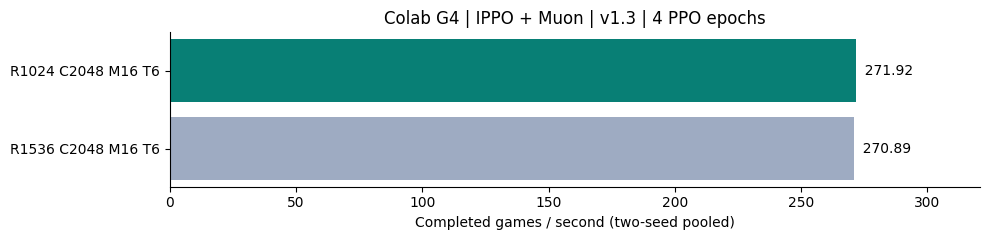

最优已测配置: {'rollout': 1024, 'collect': 2048, 'mini_batches': 16, 'threads': 6}；吞吐 271.92 对局/秒；显存峰值 94.87 GiB
完整指标、失败日志、复测 checkpoint 和校验清单: /content/g4-benchmark-results/g4-ippo-muon-20261010-035940
CLI 下载包: /content/g4-ippo-muon-20261010-035940-results.zip
只优化端到端训练吞吐；批量与 mini-batch 会改变更新次数及学习行为，未验证棋力或长期收敛。
完成后请断开连接并删除 runtime；colab-cli 操作方负责 stop 并核实 usage=0。


In [ ]:
# @title 8. 查看结果、校验文件并保存完整训练结果
import matplotlib.pyplot as plt
ranked = sorted(verification, key=lambda r: r["games_per_second"])
fig, ax = plt.subplots(figsize=(10, max(2.5, len(ranked) * 0.75)))
names = [f"R{r['config']['rollout']} C{r['config']['collect']} M{r['config']['mini_batches']} T{r['config']['threads']}" for r in ranked]
ax.barh(names, [r["games_per_second"] for r in ranked], color=["#9EABC2"] * (len(ranked) - 1) + ["#087F75"])
for i, result in enumerate(ranked):
    ax.text(result["games_per_second"], i, f"  {result['games_per_second']:.2f}", va="center")
ax.set_xlim(0, max(r["games_per_second"] for r in ranked) * 1.18)
ax.set_xlabel("Completed games / second (two-seed pooled)")
ax.set_title("Colab G4 | IPPO + Muon | v1.3 | 4 PPO epochs")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(OUTPUT / "verified-throughput.png", dpi=180)
plt.show()
plt.close(fig)
for result in results:
    assert (OUTPUT / result["label"] / "train-config.json").is_file()
    assert (OUTPUT / result["label"] / "result.json").is_file()
for checkpoint in best["checkpoint_files"]:
    assert (OUTPUT / checkpoint).stat().st_size > 0
manifest = [{"path": str(p.relative_to(OUTPUT)), "bytes": p.stat().st_size,
             "sha256": hashlib.file_digest(p.open("rb"), "sha256").hexdigest()}
            for p in sorted(OUTPUT.rglob("*")) if p.is_file() and p.name != "manifest.json"]
(OUTPUT / "manifest.json").write_text(json.dumps(manifest, indent=2))
save_archive()
print(f"最优已测配置: {best['config']}；吞吐 {best['games_per_second']:.2f} 对局/秒；显存峰值 {best['gpu_peak_mib']/1024:.2f} GiB")
print(f"完整指标、失败日志、复测 checkpoint 和校验清单: {OUTPUT}")
print(f"CLI 下载包: /content/{RUN_ID}-results.zip")
print(summary["caveat"])
print("完成后请断开连接并删除 runtime；colab-cli 操作方负责 stop 并核实 usage=0。")